# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)
print(patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color(
            "program:N",
            title="Program"
        ),
        shape=alt.Shape(
            "program:N",
            title="Program"
        ),
        tooltip=[
            "patient_id:N",
            "program:N",
            "sessions_attended:Q",
            "walk_distance_m:Q"
        ]
    )
    .properties(
        title="Session attendance and discharge walking distance"
    )
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)
exploratory_chart

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

This chart explores whether attending more rehab sessions is associated with longer walking distances in the two programs. Each point represents one patient, and both programs show a positive trend. With only 12 patients and no random assignment, the chart cannot establish causation.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


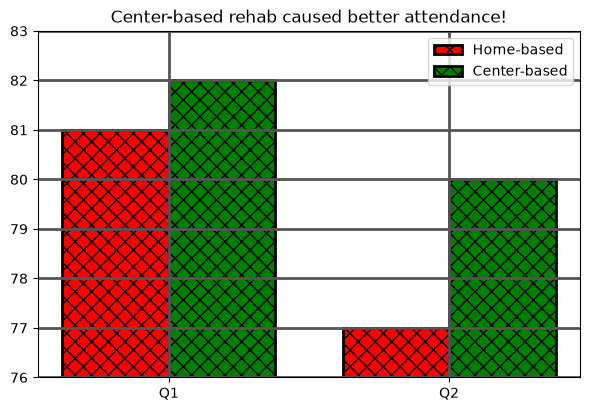

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", "problem": "The title claims causation, which these data cannot establish.", "repair": "Use a descriptive title without a causal claim."},
    {"category": "truncated baseline", "problem": "Starting the y-axis at 76 exaggerates small differences.", "repair": "Set the y-axis from 0 to 100."},
    {"category": "missing unit", "problem": "The y-axis does not explain what the percentages measure.", "repair": "Label it 'Scheduled sessions attended (%)'."},
    {"category": "color-only encoding", "problem": "Identical hatches make the programs distinguishable only by color.", "repair": "Use different colors and hatches for each program."},
    {"category": "distracting decoration", "problem": "Thick edges and heavy grid lines distract from the data.", "repair": "Use thin edges, remove the heavy grid, and hide the top and right spines."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title claims causation, which these data cannot establish.
    repair: Use a descriptive title without a causal claim.
truncated baseline: Starting the y-axis at 76 exaggerates small differences.
    repair: Set the y-axis from 0 to 100.
missing unit: The y-axis does not explain what the percentages measure.
    repair: Label it 'Scheduled sessions attended (%)'.
color-only encoding: Identical hatches make the programs distinguishable only by color.
    repair: Use different colors and hatches for each program.
distracting decoration: Thick edges and heavy grid lines distract from the data.
    repair: Use thin edges, remove the heavy grid, and hide the top and right spines.


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

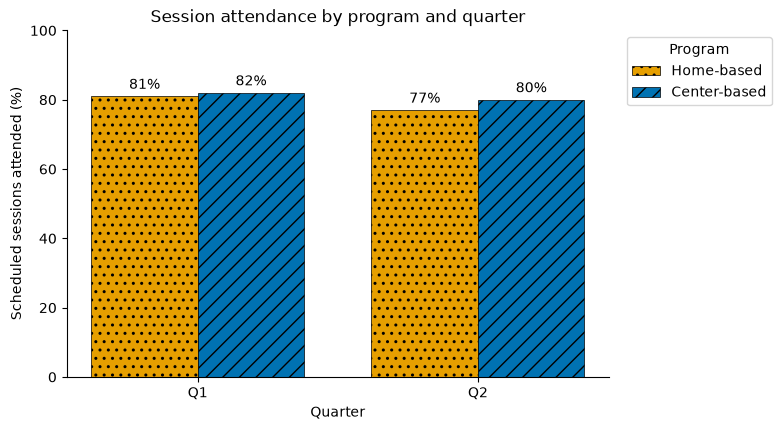

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch="..",
    edgecolor="black",
    linewidth=0.5
)

center_bars = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE,
    hatch="//",
    edgecolor="black",
    linewidth=0.5
)

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_ylim(0, 100)

redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Session attendance by program and quarter")

redesign_ax.bar_label(home_bars, fmt="%d%%", padding=3)
redesign_ax.bar_label(center_bars, fmt="%d%%", padding=3)

redesign_ax.grid(False)
redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

redesign_ax.legend(title="Program", loc="upper left", bbox_to_anchor=(1.02, 1))
redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = (
    "How does the percentage of patients meeting the weekly "
    "150-minute exercise goal change across four follow-up visits "
    "in the Home-based and Center-based programs?"
)

audience = (
    "The cardiac rehabilitation program coordinator, who will use "
    "the comparison to decide where to add follow-up support."
)

intended_claim = (
    "Both programs show higher exercise-goal attainment at visit 4 "
    "than at visit 1; at visit 4, Center-based is 79% and Home-based "
    "is 70%, a 9-percentage-point gap."
)

y_measure = (
    "Percentage of patients seen at each follow-up visit who met "
    "the weekly 150-minute exercise goal (%)."
)

grain = (
    "Each row of the plotting table and each point on a line "
    "represents one program at one follow-up visit."
)

data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[
    ["program", "visit_number", "goal_met_pct"]
].copy()

supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

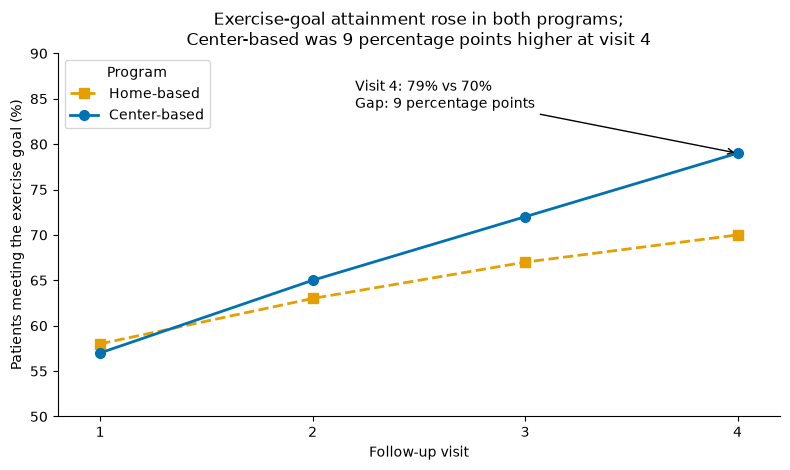

In [7]:
home_goals = supporting_data.loc[
    supporting_data["program"] == "Home-based"
]

center_goals = supporting_data.loc[
    supporting_data["program"] == "Center-based"
]

explanatory_fig, explanatory_ax = plt.subplots(
    figsize=(8, 4.8)
)

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE,
    marker="s",
    linestyle="--",
    linewidth=2,
    markersize=7,
    label="Home-based"
)

explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE,
    marker="o",
    linestyle="-",
    linewidth=2,
    markersize=7,
    label="Center-based"
)

explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel(
    "Patients meeting the exercise goal (%)"
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_xlim(0.8, 4.2)
explanatory_ax.set_ylim(50, 90)

explanatory_ax.set_title(
    "Exercise-goal attainment rose in both programs;\n"
    "Center-based was 9 percentage points higher at visit 4"
)

explanatory_ax.annotate(
    "Visit 4: 79% vs 70%\nGap: 9 percentage points",
    xy=(4, 79),
    xytext=(2.2, 84),
    arrowprops={
        "arrowstyle": "->",
        "color": "black"
    },
    fontsize=10
)

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)
explanatory_ax.legend(title="Program", loc="upper left")

explanatory_fig.tight_layout()
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = (
    "This line chart shows the percentage of patients meeting the "
    "weekly 150-minute exercise goal across four follow-up visits "
    "for the Home-based and Center-based programs. The x-axis shows "
    "follow-up visits 1 through 4, and the y-axis shows the percentage "
    "of patients seen at each visit who met the goal. Home-based "
    "increases from 58% at visit 1 to 70% at visit 4, while Center-based "
    "increases from 57% to 79%. At visit 4, Center-based is 9 percentage "
    "points higher than Home-based, 79% versus 70%. Patients chose "
    "their program, so this comparison does not show that either "
    "program causes more exercise. Each percentage describes only "
    "the patients seen at that visit, about 45 per program at visit 4, "
    "so the 9-point gap could also reflect chance or differences in "
    "who returned for follow-up."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(
        visualization_evidence,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)


with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

1. Different hatches distinguish the bars, different markers and line styles distinguish the lines in grayscale.
2. The annotation points to (4, 79) and describes the 9-percentage-point gap without claiming causation.
3. Neither saved PNG has cut-off or overlapping text, so no changes were needed.
4. Small samples, self-selection, and differences in who returned limit interpretation and prevent causal conclusions.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m